# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Олійник Божена Орестівна'     # група ШІ-33
LIST_NUMBER  = 7      # номер у списку групи

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 7, файл lr6_варіант_07.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [ ]:
TYPE_OF_TASK = 'класифікація'      # 'класифікація' / 'регресія' / 'кластеризація' / 'зменшення розмірності'
# чому: ціль «відтік» бінарна (1 — розірвав договір, 0 — лишився), треба оцінити ризик належності до класу 1.

METRIC = 'AUC'            # 'точність' / 'AUC' / 'F1' / 'повнота' / 'MAE'
# чому саме ця, а не точність: класи незбалансовані (відтік 15–30 %), тож модель «ніхто не піде» має точність 70–85 % при нульовій користі; AUC не залежить від порога і оцінює саме ранжування клієнтів за ризиком.

CV_SCHEME = 'стратифікована 5-кратна, 4 повтори'         # напр. 'стратифікована 5-кратна, 4 повтори'
# чому саме така: стратифікація зберігає частку відтоку в кожній згортці, а 4 повтори дають 20 оцінок — середнє і розкид, потрібні для парного порівняння моделей.

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')

рішення зафіксовані


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [5]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.294

типи стовпців: {'str': 13, 'float64': 7, 'int64': 6}


In [ ]:
overview = pd.DataFrame({
    'тип': raw.dtypes.astype(str),
    'унікальних': raw.nunique(),
    '% пропусків': (raw.isna().mean() * 100).round(1),
    'приклад': raw.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
})
overview.index.name = 'стовпець'
overview = overview.sort_values('% пропусків', ascending=False)
pd.set_option('display.max_rows', 100)
display(overview)

print('частка відтоку: %.3f; точність моделі «ніхто не піде»: %.3f'
      % (raw[TARGET].mean(), 1 - raw[TARGET].mean()))
print('стовпців невизначеного (текстового) типу:',
      int((~raw.dtypes.map(pd.api.types.is_numeric_dtype)).sum()))

,тип,унікальних,% пропусків,приклад
стовпець,,,,
код_причини_закриття,str,5,70.6,ПЕР-01
сума_повернення_депозиту,float64,349,70.6,179.69
середній_час_відповіді_хв,float64,276,30.5,22.7
трафік_ГБ,str,975,5.0,142.6
щомісячний_платіж,str,1136,4.0,329.5
аварій_на_ділянці_за_квартал,float64,6,3.0,1.0
стать,str,6,0.0,Ч
місто,str,6,0.0,Самбір
id_клієнта,str,1200,0.0,K70000


частка відтоку: 0.294; точність моделі «ніхто не піде»: 0.706
стовпців невизначеного (текстового) типу: 13


### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [7]:
# ----- ВАШ КОД: знайдіть і покажіть по кілька прикладів кожної проблеми -----
date_re = r'^\s*\d{4}-\d{2}-\d{2}'
txt_cols = [c for c in raw.columns if not pd.api.types.is_numeric_dtype(raw[c])]
rows = []
for c in txt_cols:
    s = raw[c].dropna().astype(str).str.strip()
    as_num = pd.to_numeric(s, errors='coerce')
    rows.append({'стовпець': c,
                 'чисте число': int(as_num.notna().sum()),
                 'число + текст': int((as_num.isna() & s.str.match(r'^-?\d+([.,]\d+)?\s*\D+$')).sum()),
                 'схоже на дату': int(s.str.match(date_re).sum()),
                 'усього заповнено': len(s)})
display(pd.DataFrame(rows).set_index('стовпець'))

# 1) числова колонка, де частина значень записана текстом
s = raw['щомісячний_платіж'].dropna().astype(str)
print('1) щомісячний_платіж, приклади з текстом:',
      s[pd.to_numeric(s, errors='coerce').isna()].head(5).tolist())

# 2) колонка, де Excel перетворив число на дату
s = raw['трафік_ГБ'].dropna().astype(str)
print('2) трафік_ГБ, приклади-дати:', s[s.str.match(date_re)].tolist())

# 3) колонка з невипадковими пропусками
miss = raw['середній_час_відповіді_хв'].isna()
print('3) середній_час_відповіді_хв: пропусків %d' % miss.sum())
display(raw.groupby(miss.map({True: 'пропуск', False: 'заповнено'}))
        .agg(звернень_мін=('кількість_звернень_у_підтримку', 'min'),
             звернень_макс=('кількість_звернень_у_підтримку', 'max'),
             частка_відтоку=(TARGET, 'mean'),
             клієнтів=(TARGET, 'size')))

,чисте число,число + текст,схоже на дату,усього заповнено
стовпець,,,,
id_клієнта,0,0,0,1200
стать,0,0,0,1200
місто,0,0,0,1200
філія,0,0,0,1200
тариф,0,0,0,1200
тип_підключення,0,0,0,1200
спосіб_оплати,0,0,0,1200
автоплатіж,0,0,0,1200
щомісячний_платіж,1124,28,0,1152


1) щомісячний_платіж, приклади з текстом: ['319.08 грн', '341.57 грн', '342.33 грн', '272.93 грн', '407.16 грн']
2) трафік_ГБ, приклади-дати: ['1900-01-18 00:00:00', '1900-01-15 00:00:00', '1900-01-24 00:00:00']
3) середній_час_відповіді_хв: пропусків 366


,звернень_мін,звернень_макс,частка_відтоку,клієнтів
середній_час_відповіді_хв,,,,
заповнено,1,8,0.314149,834
пропуск,0,0,0.248634,366


In [8]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'    # назва стовпця
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'    # назва стовпця
PROBLEM_MNAR           = 'середній_час_відповіді_хв'    # назва стовпця
MNAR_MEANING           = 'Пропуск означає, що клієнт жодного разу не звертався в підтримку (у всіх клієнтів із пропуском кількість_звернень_у_підтримку = 0), тож часу відповіді для нього просто не існує.'    # що означає сам факт пропуску, одним реченням

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')

проблеми названо


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [9]:
def to_number(s):
    """Витягує число з колонки, де перемішані числа, текст і дати."""
    def one(v):
        # ----- ВАШ КОД -----
        # 2) datetime / Timestamp  -> np.nan   (це брак, а не дані)
        if isinstance(v, (datetime.datetime, datetime.date, np.datetime64)):
            return np.nan
        # 1) None / NaN            -> np.nan
        if v is None or (not isinstance(v, str) and pd.isna(v)):
            return np.nan
        # 3) число                 -> float
        if isinstance(v, (int, float, np.integer, np.floating)):
            return float(v)
        # 4) текст                 -> перше число в ньому, інакше np.nan
        t = str(v).strip()
        if re.match(r'^\d{4}-\d{2}-\d{2}', t):     # дата, яку Excel зробив із числа, записана текстом
            return np.nan
        m = re.search(r'\d+(?:[.,]\d+)?', t)
        return float(m.group().replace(',', '.')) if m else np.nan
    return s.map(one)


# самоперевірка
_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
print('to_number працює')

to_number працює


In [10]:
DROP_ALWAYS = ['id_клієнта']   # ідентифікатор: нічого не пояснює, лише запам'ятовується

def build_X(d, drop):
    """Сира таблиця -> матриця ознак. Категорії лишаємо типом category."""
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        # ----- ВАШ КОД -----
        s = d[c]
        if c == 'дата_підключення':
            # дата_підключення -> число (порядковий номер дня)
            dt = pd.to_datetime(s, errors='coerce')
            X[c] = dt.map(lambda t: float(t.toordinal()) if pd.notna(t) else np.nan).astype(float)
            kind = 'число (день)'
        elif pd.api.types.is_numeric_dtype(s):
            # числова -> float
            X[c] = s.astype(float)
            kind = 'число'
        else:
            st = s.dropna().astype(str).str.strip()
            num = to_number(s)
            # «розбирається в число» = значення починається з числа і to_number його дістав
            parsed = (st.str.match(r'^-?\d') & num[st.index].notna()).sum()
            if len(st) and parsed > 0.8 * len(st):
                # текстова колонка, де >80% значень розбираються в число -> число
                X[c] = num.astype(float)
                kind = 'число з тексту'
            else:
                # інша текстова -> category (регістр і пробіли приведено)
                X[c] = s.astype(str).str.strip().str.lower().where(s.notna()).astype('category')
                kind = 'категорія'
        log.append({'стовпець': c, 'рішення': kind,
                    'пропусків після': int(X[c].isna().sum())})
    return X, pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 9


,стовпець,рішення,пропусків після
0,вік,число,0
1,стать,категорія,0
2,місто,категорія,0
3,філія,категорія,0
4,тариф,категорія,0
5,тип_підключення,категорія,0
6,спосіб_оплати,категорія,0
7,автоплатіж,категорія,0
8,кількість_послуг,число,0
9,місяців_обслуговування,число,0


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [11]:
def make_pipe(X, clf):
    # ----- ВАШ КОД -----
    cat = [c for c in X.columns if str(X[c].dtype) == 'category']
    num = [c for c in X.columns if c not in cat]
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                          ('sc', StandardScaler())]), num),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('ohe', OneHotEncoder(handle_unknown='ignore'))]), cat),
    ], sparse_threshold=0)   # щільна матриця: гістограмний бустинг і SHAP не приймають розріджену
    return Pipeline([('prep', prep), ('clf', clf)])


def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

# самоперевірка: конвеєр має бути єдиним оцінювачем і переживати крос-валідацію
_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 0.985


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [12]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 0.984 ± 0.005
час      : 0.6 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [13]:
FIRST_REACTION = 'AUC 0,984 ± 0,005 — вище за 0,95, а на реальних даних це майже завжди ознака витоку, а не надзвичайно легкої задачі: найімовірніше, у таблиці є стовпці, які записані вже після того, як клієнт пішов.'
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

AUC 0,984 ± 0,005 — вище за 0,95, а на реальних даних це майже завжди ознака витоку, а не надзвичайно легкої задачі: найімовірніше, у таблиці є стовпці, які записані вже після того, як клієнт пішов.


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [14]:
def leak_scan(d, y, min_group=20):
    """Для кожного стовпця: наскільки добре його заповненість вгадує клас.

    Повертає таблицю зі стовпцями: ознака, заповнено, частка_відтоку_де_заповнено,
    частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    """
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        # ----- ВАШ КОД -----
        filled = d[c].notna()
        n_f, n_m = int(filled.sum()), int((~filled).sum())
        score = np.nan
        if n_f > min_group and n_m > min_group:     # обидві групи більші за min_group
            score = roc_auc_score(y, filled.astype(int))
        rows.append({'ознака': c, 'заповнено': n_f,
                     'частка_відтоку_де_заповнено': y[filled].mean() if n_f else np.nan,
                     'частка_відтоку_де_пропуск': y[~filled].mean() if n_m else np.nan,
                     'показник': score})
    return pd.DataFrame(rows).sort_values('показник', ascending=False)


scan = leak_scan(raw, y)
display(scan.head(10))

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
22,сума_повернення_депозиту,353,1.000000,0.000000,1.000000
23,код_причини_закриття,353,1.000000,0.000000,1.000000
17,середній_час_відповіді_хв,834,0.314149,0.248634,0.533442
16,аварій_на_ділянці_за_квартал,1164,0.295533,0.250000,0.503191
12,щомісячний_платіж,1152,0.292535,0.333333,0.496227
14,трафік_ГБ,1140,0.292105,0.333333,0.495284
0,id_клієнта,1200,0.294167,NaN,NaN
1,вік,1200,0.294167,NaN,NaN
2,стать,1200,0.294167,NaN,NaN
3,місто,1200,0.294167,NaN,NaN


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [15]:
TARGET_LEAK = [
    'сума_повернення_депозиту',   # депозит повертають лише при закритті договору — значення з'являється після розірвання
    'код_причини_закриття',       # причину закриття вписують у момент розірвання договору — до того поле порожнє
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)

цільовий витік: ['сума_повернення_депозиту', 'код_причини_закриття']


In [16]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.923 ± 0.013


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [17]:
# ----- ВАШ КОД: перегляньте список стовпців, що лишились -----
print(list(X2.columns))

# питання до кожного «невідомого» стовпця: коли він з'являється?
for c in ['кількість_дзвінків_утримання', 'скоринг_партнера', 'код_тарифного_плану', 'трафік_МБ']:
    print()
    print(c, '— пропусків:', raw[c].isna().sum(), ', унікальних:', raw[c].nunique())
display(raw.groupby('кількість_дзвінків_утримання')[TARGET].agg(['mean', 'size'])
        .rename(columns={'mean': 'частка_відтоку', 'size': 'клієнтів'}))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'трафік_МБ', 'код_тарифного_плану', 'скоринг_партнера', 'дата_підключення', 'кількість_дзвінків_утримання']

кількість_дзвінків_утримання — пропусків: 0 , унікальних: 6

скоринг_партнера — пропусків: 0 , унікальних: 1199

код_тарифного_плану — пропусків: 0 , унікальних: 40

трафік_МБ — пропусків: 0 , унікальних: 1200


,частка_відтоку,клієнтів
кількість_дзвінків_утримання,,
0,0.073935,798
1,0.632184,87
2,0.769231,91
3,0.736111,72
4,0.753247,77
5,0.773333,75


In [18]:
HUMAN_LEAK = [
    'кількість_дзвінків_утримання',   # заповнює відділ утримання: дзвонить клієнтові ПІСЛЯ того, як побачив, що той збирається піти (заява, скарги), — тобто вже після сигналу про відтік
]
HUMAN_LEAK_WHY = 'Поле заповнене в усіх 1200 клієнтів (у кого дзвінків не було — стоїть 0), пропусків немає, тож детектор, який дивиться на факт заповненості, не має з чим порівнювати (група пропусків порожня, менша за min_group) і показника не дає; формально це не наслідок відтоку, але дзвінки утримання робить людина, яка вже побачила, що клієнт збирається піти: при 0 дзвінків відтік 0,074, при 1–5 дзвінках 0,63–0,77.'      # чому детектор із 5.1 його не спіймав

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))

після вилучення оцінок людини: 21 ознак, AUC 0.816 ± 0.026


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

,частка_відтоку,клієнтів
філія,,
Ф-01 Центр,0.254,177
Ф-02 Захід,0.266,207
Ф-03 Схід,0.321,212
Ф-04 Південь,0.340,206
Ф-05 Північ,0.271,203
Ф-06 Приміська,0.308,195


,частка_відтоку,клієнтів
дата_підключення,,
2023Q1,0.230,148
2023Q2,0.202,178
2023Q3,0.212,151
2023Q4,0.230,161
2024Q1,0.154,130
2024Q2,0.471,138
2024Q3,0.434,152
2024Q4,0.444,142


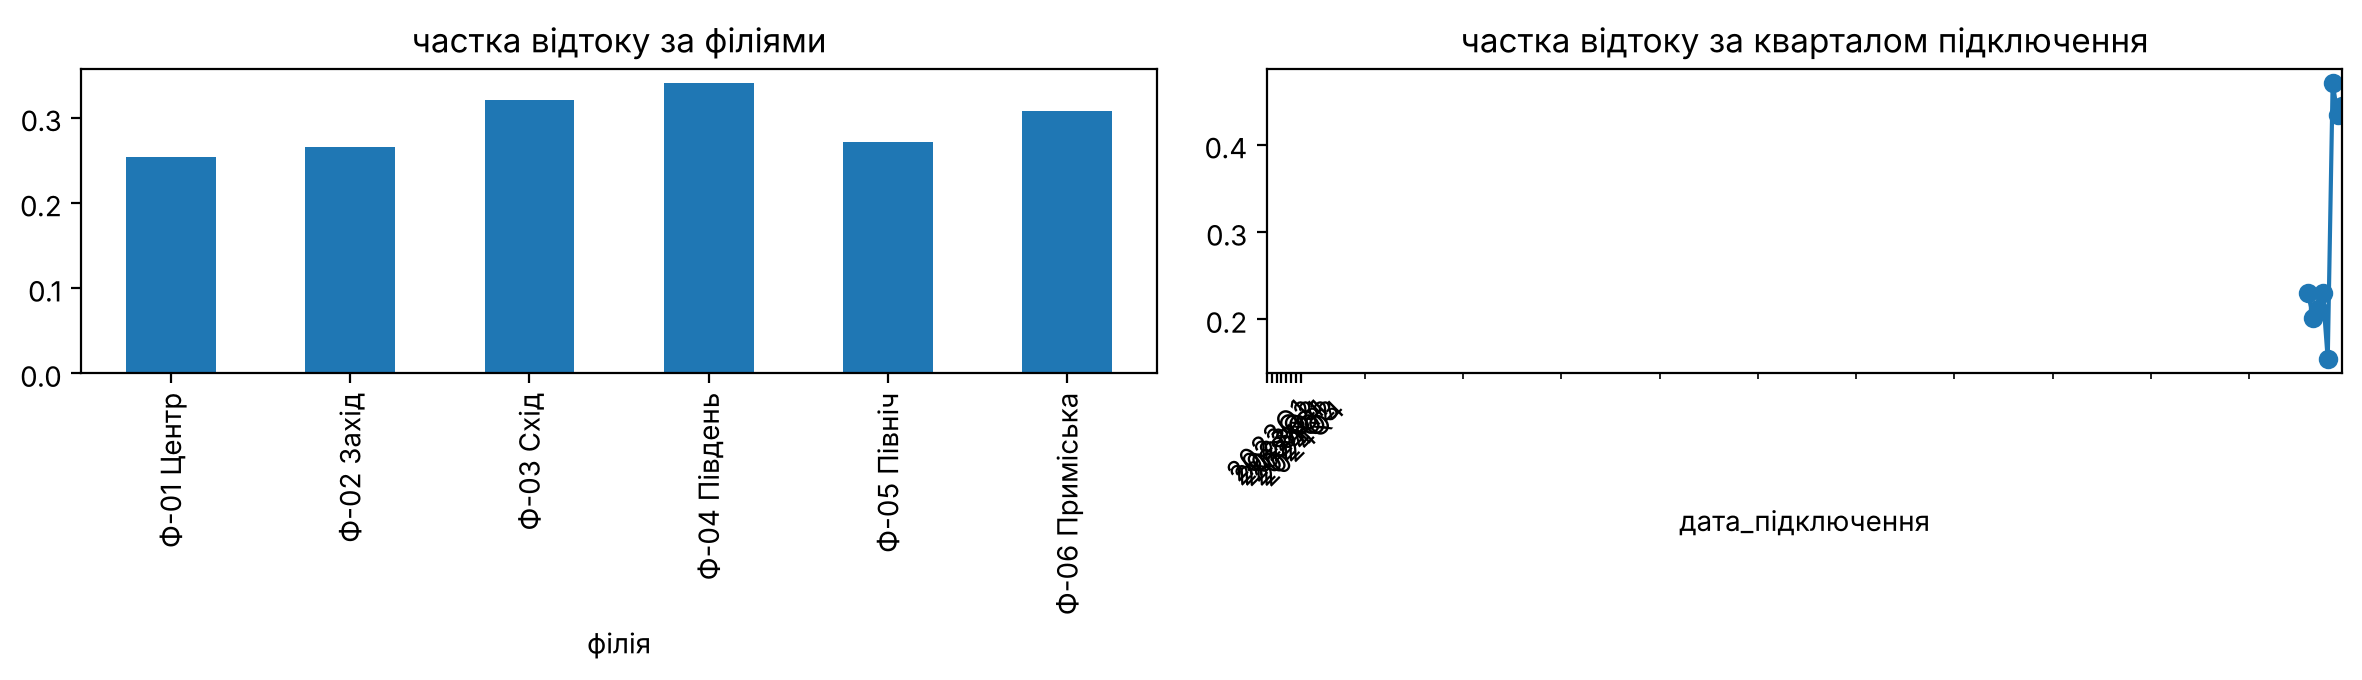

In [19]:
# ----- ВАШ КОД -----
# 1) частка відтоку за кожною філією (і скільки клієнтів у кожній);
by_branch = raw.groupby('філія')[TARGET].agg(['mean', 'size']).rename(
    columns={'mean': 'частка_відтоку', 'size': 'клієнтів'}).round(3)
display(by_branch)

# 2) частка відтоку по кварталах дати підключення — таблицею або графіком.
conn_q = pd.to_datetime(raw['дата_підключення'], errors='coerce').dt.to_period('Q')
by_q = raw.groupby(conn_q)[TARGET].agg(['mean', 'size']).rename(
    columns={'mean': 'частка_відтоку', 'size': 'клієнтів'}).round(3)
display(by_q)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
by_branch['частка_відтоку'].plot.bar(ax=ax[0], title='частка відтоку за філіями')
by_q['частка_відтоку'].plot(ax=ax[1], marker='o', title='частка відтоку за кварталом підключення')
ax[1].set_xticks(range(len(by_q))); ax[1].set_xticklabels(by_q.index.astype(str), rotation=45)
plt.tight_layout(); plt.show()
# Шукайте СХОДИНКУ, а не плавну зміну.

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [20]:
SUSPECT = 'дата_підключення'        # 'філія' або 'дата_підключення' — що саме ви підозрюєте
assert SUSPECT in ('філія', 'дата_підключення')

# ----- ВАШ КОД: побудуйте бінарну змінну source -----
# для 'дата_підключення': 1 для клієнтів, підключених після дати-зламу
BREAK_DATE = '2024-04-01'   # сходинка між 2024Q1 і 2024Q2 у таблиці 6.1
source = (pd.to_datetime(raw['дата_підключення'], errors='coerce') >= BREAK_DATE).astype(int)
print('після дати-зламу: %d клієнтів, відтік %.3f; до: %d клієнтів, відтік %.3f'
      % (source.sum(), y[source == 1].mean(), (source == 0).sum(), y[source == 0].mean()))

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

після дати-зламу: 432 клієнтів, відтік 0.449; до: 768 клієнтів, відтік 0.207


ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.784
ті самі ознаки передбачають ВІДТІК  : AUC 0.792 ± 0.028


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [21]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,0.984
2. мінус цільовий витік,22,0.923
3. мінус оцінки людини,21,0.816
4. мінус артефакт збору,20,0.792


чесне число: 0.792 ± 0.028


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [22]:
DECISION_ARTEFACT = 'викинути'    # 'викинути' / 'залишити' / 'залишити, але звітувати окремо'
DECISION_WHY = 'Частка відтоку за кварталом підключення дає сходинку, а не плавну зміну: 2024Q1 — 0,154, 2024Q2 — 0,471 і далі 0,43–0,44, тобто з 2024-04-01 змінилось правило обліку, а не поведінка клієнтів; модель має працювати на нових клієнтах, а з датою вона частково вгадувала б період обліку, а не відтік (ціною вилучення AUC 0,816 → 0,792).'
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)

викинути — Частка відтоку за кварталом підключення дає сходинку, а не плавну зміну: 2024Q1 — 0,154, 2024Q2 — 0,471 і далі 0,43–0,44, тобто з 2024-04-01 змінилось правило обліку, а не поведінка клієнтів; модель має працювати на нових клієнтах, а з датою вона частково вгадувала б період обліку, а не відтік (ціною вилучення AUC 0,816 → 0,792).


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [23]:
from sklearn.tree import DecisionTreeClassifier

MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(random_state=SEED),
    'випадковий ліс':       RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    'гістограмний бустинг': HistGradientBoostingClassifier(random_state=SEED),
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round((time.time() - t0) * 100 / len(a), 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.792,0.028,3.0
одне дерево,0.631,0.028,3.2
випадковий ліс,0.795,0.027,61.3
гістограмний бустинг,0.787,0.031,33.1


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [24]:
def paired(a, b):
    """Повертає (середня різниця, півширина 95% інтервалу)."""
    # ----- ВАШ КОД -----
    from scipy import stats
    d = np.asarray(b) - np.asarray(a)          # різниця на тих самих поділах
    h = stats.t.ppf(0.975, len(d) - 1) * d.std(ddof=1) / np.sqrt(len(d))
    return float(d.mean()), float(h)


base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: +0.0029 ± 0.0094   у межах шуму


гістограмний бустинг   проти логістичної: -0.0054 ± 0.0099   у межах шуму


In [25]:
CHOSEN_MODEL = 'логістична регресія'     # назва з MODELS
CHOSEN_WHY = 'Якість: AUC 0,792 ± 0,028, а ліс (0,795) і бустинг (0,787) відрізняються від неї в межах шуму (+0,0029 ± 0,0094 і −0,0054 ± 0,0099); час: у ~20 разів швидша за ліс; інтерпретованість: коефіцієнти читаються напряму; стабільність: розкид такий самий, як у складніших моделей.'       # за якими з чотирьох критеріїв і чому саме так
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)

обрано: логістична регресія — Якість: AUC 0,792 ± 0,028, а ліс (0,795) і бустинг (0,787) відрізняються від неї в межах шуму (+0,0029 ± 0,0094 і −0,0054 ± 0,0099); час: у ~20 разів швидша за ліс; інтерпретованість: коефіцієнти читаються напряму; стабільність: розкид такий самий, як у складніших моделей.


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [26]:
def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F = X.copy()
    # ----- ВАШ КОД: щонайменше три ознаки, кожна з коментарем-гіпотезою -----
    # гіпотеза: клієнт, який платить багато за кожен Мбіт/с (переплачує), шукатиме дешевшого провайдера
    F['переплата_грн_за_Мбіт'] = F['щомісячний_платіж'] / F['швидкість_тарифу_Мбіт']
    # гіпотеза: важлива не кількість звернень, а їхня частота — часті проблеми за короткий стаж штовхають до відходу
    F['звернень_на_місяць'] = F['кількість_звернень_у_підтримку'] / (F['місяців_обслуговування'] + 1)
    # гіпотеза: сам факт наявності знижки утримує клієнта, незалежно від її розміру
    F['є_знижка'] = (F['знижка_відсоток'] > 0).astype(float)
    return F


X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))

було 20 ознак, стало 23


In [27]:
t0 = time.time()
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
t_feat = time.time() - t0
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))
print('час 20 навчань логістичної регресії з новими ознаками: %.1f c' % t_feat)

з новими ознаками: AUC 0.790 ± 0.028
приріст проти базового набору: -0.0026 ± 0.0014   значуще
час 20 навчань логістичної регресії з новими ознаками: 0.6 c


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [28]:
FEATURES_VS_MODEL = 'Жоден шлях не дав значущого приросту: три нові ознаки змінили AUC логістичної регресії на −0,0026 ± 0,0014 (значуще, але вниз) майже без додаткового часу (~0,6 с на 20 навчань), а складніша модель — випадковий ліс — дала +0,0029 ± 0,0094 (у межах шуму) ціною ~58 с на 100 навчань проти ~3 с у логістичної.'
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

Жоден шлях не дав значущого приросту: три нові ознаки змінили AUC логістичної регресії на −0,0026 ± 0,0014 (значуще, але вниз) майже без додаткового часу (~0,6 с на 20 навчань), а складніша модель — випадковий ліс — дала +0,0029 ± 0,0094 (у межах шуму) ціною ~58 с на 100 навчань проти ~3 с у логістичної.


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [29]:
FINAL_X = X5                      # з якою матрицею працюємо далі
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.787
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

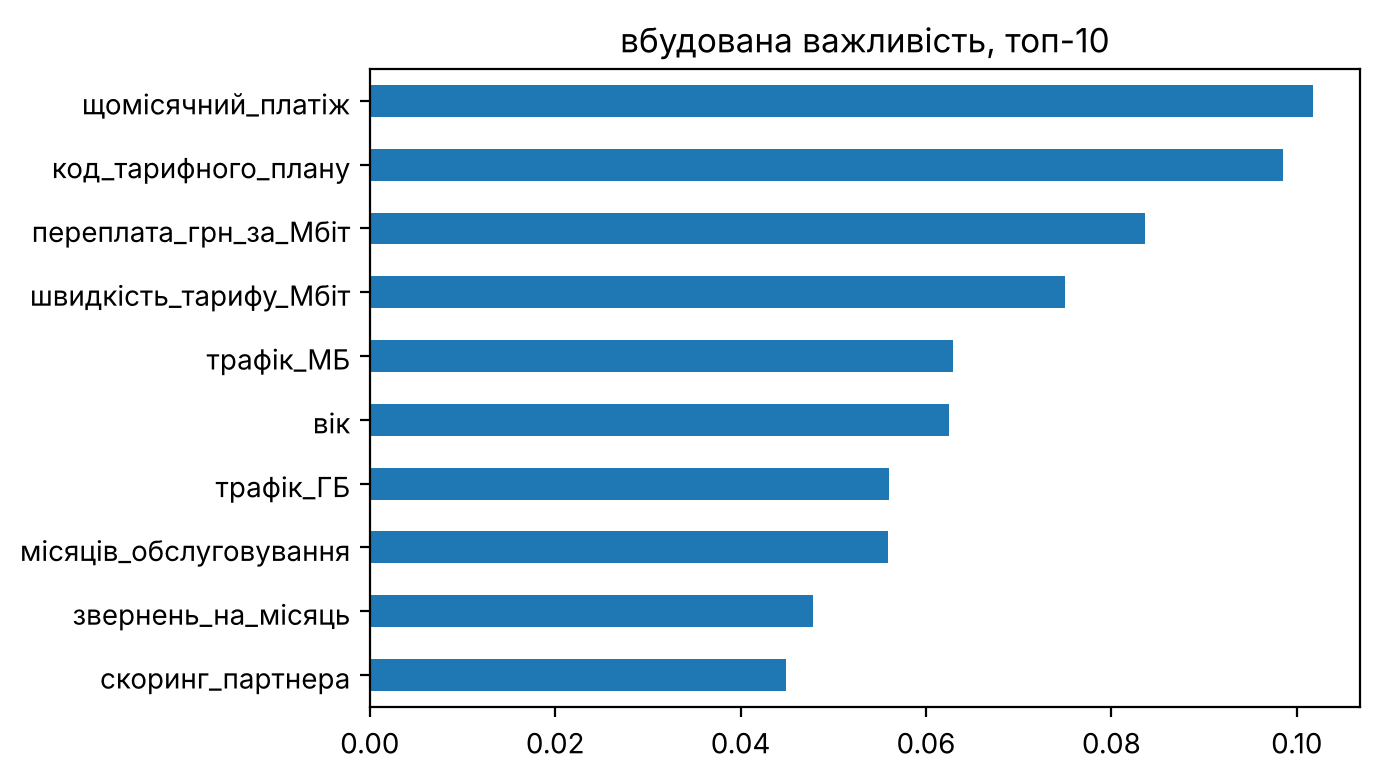

In [30]:
# ----- ВАШ КОД -----
# 1) дістаньте імена після перетворення: model.named_steps['prep'].get_feature_names_out()
names_t = model.named_steps['prep'].get_feature_names_out()
imp_t = model.named_steps['clf'].feature_importances_

# 2) підсумуйте важливості дамі-стовпців до вихідних ознак
cat_cols = [c for c in FINAL_X.columns if str(FINAL_X[c].dtype) == 'category']
def to_orig(n):
    block, rest = n.split('__', 1)
    if block == 'cat':
        for c in sorted(cat_cols, key=len, reverse=True):
            if rest.startswith(c + '_'):
                return c
    return rest
gini_imp = (pd.Series(imp_t, index=[to_orig(n) for n in names_t])
            .groupby(level=0).sum().sort_values(ascending=False))

# 3) побудуйте горизонтальну стовпчикову діаграму топ-10
gini_imp.head(10)[::-1].plot.barh(figsize=(7, 4), title='вбудована важливість, топ-10')
plt.tight_layout(); plt.show()

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [31]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
вік,0.050741
трафік_МБ,0.030889
щомісячний_платіж,0.025253
місяців_обслуговування,0.021700
швидкість_тарифу_Мбіт,0.020957
трафік_ГБ,0.016957
кількість_послуг,0.009908
звернень_на_місяць,0.008140
скоринг_партнера,0.005584
автоплатіж,0.003983


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [32]:
# ----- ВАШ КОД: таблиця «ознака | вбудована | перестановочна», відсортована за вбудованою -----
imp_table = pd.DataFrame({'вбудована': gini_imp, 'перестановочна': perm_imp})
imp_table.index.name = 'ознака'
imp_table = imp_table.sort_values('вбудована', ascending=False).round(4)
display(imp_table)

,вбудована,перестановочна
ознака,,
щомісячний_платіж,0.1017,0.0253
код_тарифного_плану,0.0985,-0.0009
переплата_грн_за_Мбіт,0.0836,0.0025
швидкість_тарифу_Мбіт,0.0750,0.0210
трафік_МБ,0.0629,0.0309
вік,0.0625,0.0507
трафік_ГБ,0.0560,0.0170
місяців_обслуговування,0.0559,0.0217
звернень_на_місяць,0.0479,0.0081


In [33]:
FAKE_IMPORTANT = 'код_тарифного_плану'        # назва ознаки
FAKE_IMPORTANT_WHY = 'Вбудована важливість 0,0985 (2-ге місце), перестановочна −0,0009: після одиничного кодування 40 рівнів дають дереву 40 стовпців і багато можливих розбиттів, на навчальних даних серед них майже завжди знаходиться таке, що трохи зменшує неоднорідність; ці дрібні зменшення сумуються, хоча зв’язку з відтоком немає — на перевірковій частині перемішування ознаки якість не погіршує.'    # чому вбудована важливість її переоцінює
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)

хибно важлива ознака: код_тарифного_плану


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [34]:
# ----- ВАШ КОД: кореляційна матриця числових ознак, знайдіть пару з |r| > 0.97 -----
num_cols = [c for c in FINAL_X.columns if str(FINAL_X[c].dtype) != 'category']
corr = FINAL_X[num_cols].corr()
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(num_cols) for b in num_cols[i + 1:]
         if abs(corr.loc[a, b]) > 0.97]
display(pd.DataFrame(pairs, columns=['ознака 1', 'ознака 2', 'r']).round(4))

,ознака 1,ознака 2,r
0,трафік_ГБ,трафік_МБ,0.9997


In [35]:
DUP_PAIR = ['трафік_МБ', 'трафік_ГБ']        # дві ознаки, що вимірюють те саме
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

# ----- ВАШ КОД: приберіть DUP_PAIR[1], навчіть заново, порахуйте перестановочну -----
# і виведіть важливість DUP_PAIR[0] без пари
Xtr_d, Xte_d = Xtr.drop(columns=[DUP_PAIR[1]]), Xte.drop(columns=[DUP_PAIR[1]])
model_d = make_pipe(Xtr_d, RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)).fit(Xtr_d, ytr)
perm_d = permutation_importance(model_d, Xte_d, yte, n_repeats=10,
                                random_state=SEED, scoring='roc_auc')
perm_imp_d = pd.Series(perm_d.importances_mean, index=Xte_d.columns)
print('без %s:' % DUP_PAIR[1])
print('   %-28s %+.4f' % (DUP_PAIR[0], perm_imp_d[DUP_PAIR[0]]))

у повній моделі:
   трафік_МБ                    +0.0309
   трафік_ГБ                    +0.0170


без трафік_ГБ:
   трафік_МБ                    +0.0538


In [36]:
DUP_EXPLANATION = 'трафік_ГБ і трафік_МБ — той самий трафік у різних одиницях (r = 0,9997). У повній моделі перестановочна важливість розділилась між ними: трафік_МБ +0,0309, трафік_ГБ +0,0170, бо при перемішуванні однієї ознаки модель частково бере ту саму інформацію з другої. Після вилучення трафік_ГБ важливість трафік_МБ зросла до +0,0538 — тепер замінити її нічим. Метод не бреше: він точно відповідає, наскільки гірше без ознаки за наявності іншої.'
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

трафік_ГБ і трафік_МБ — той самий трафік у різних одиницях (r = 0,9997). У повній моделі перестановочна важливість розділилась між ними: трафік_МБ +0,0309, трафік_ГБ +0,0170, бо при перемішуванні однієї ознаки модель частково бере ту саму інформацію з другої. Після вилучення трафік_ГБ важливість трафік_МБ зросла до +0,0538 — тепер замінити її нічим. Метод не бреше: він точно відповідає, наскільки гірше без ознаки за наявності іншої.


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

три найважливіші числові ознаки за перестановочною: ['вік', 'трафік_МБ', 'щомісячний_платіж']


щомісячний_платіж: PDP побудовано на підвибірці з 345 із 360 рядків, де ознака заповнена


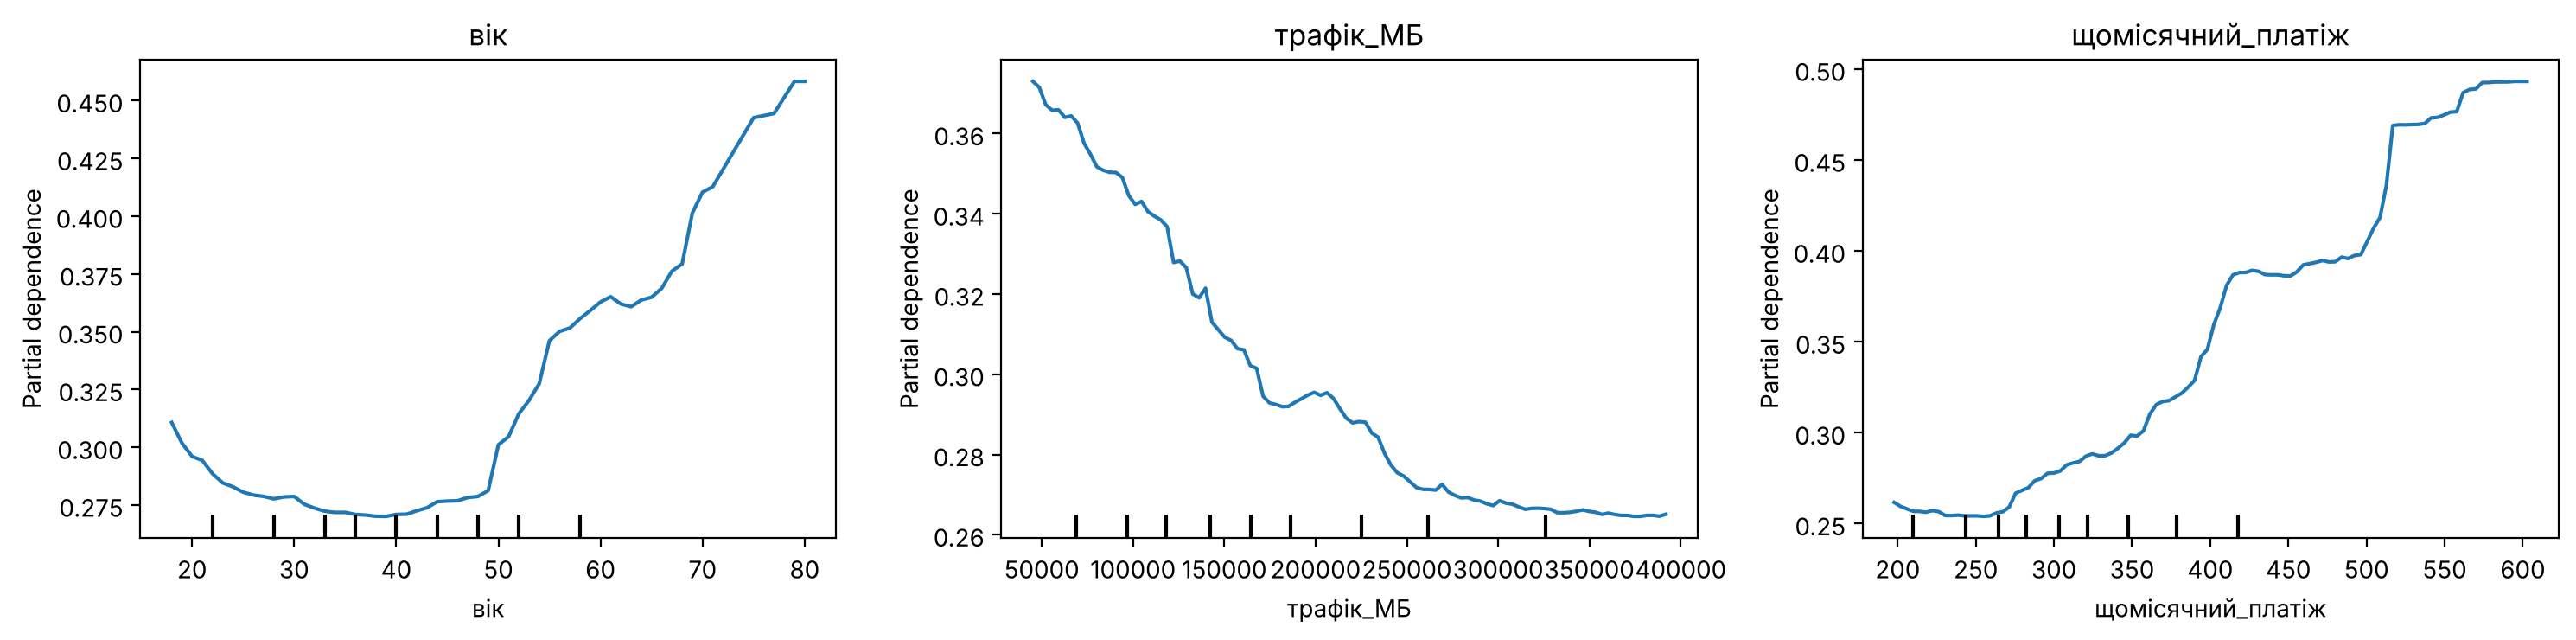

In [37]:
from sklearn.inspection import PartialDependenceDisplay

# ----- ВАШ КОД -----
num_feats = [c for c in FINAL_X.columns if str(FINAL_X[c].dtype) != 'category']
top3_num = perm_imp[num_feats].sort_values(ascending=False).head(3).index.tolist()
print('три найважливіші числові ознаки за перестановочною:', top3_num)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for f, ax in zip(top3_num, axes):
    sub = Xte[Xte[f].notna()]           # ознака з пропусками дасть порожню сітку — будуємо на підвибірці
    if len(sub) < len(Xte):
        print('%s: PDP побудовано на підвибірці з %d із %d рядків, де ознака заповнена' % (f, len(sub), len(Xte)))
    PartialDependenceDisplay.from_estimator(model, sub, features=[f], kind='average', ax=ax)
    ax.set_title(f)
plt.tight_layout(); plt.show()

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

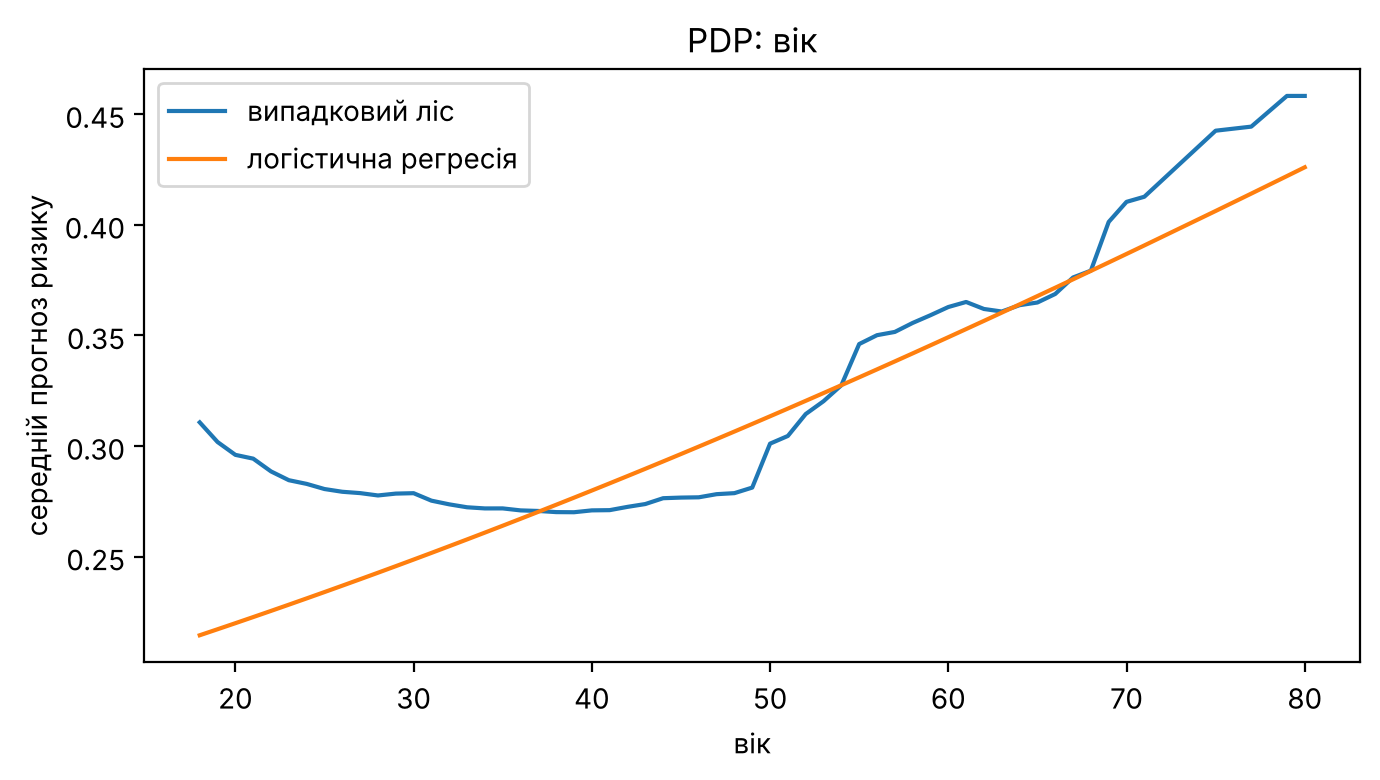

мінімум ризику в лісу при вік ≈ 39.0


In [38]:
NONLINEAR_FEATURE = 'вік'
assert NONLINEAR_FEATURE in FINAL_X.columns

# ----- ВАШ КОД: один рисунок, дві криві — ліс і логістична регресія -----
model_lr = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)
sub = Xte[Xte[NONLINEAR_FEATURE].notna()]
pd_rf = partial_dependence(model, sub, [NONLINEAR_FEATURE], kind='average')
pd_lr = partial_dependence(model_lr, sub, [NONLINEAR_FEATURE], kind='average')
grid_rf = pd_rf['grid_values'][0]; curve_rf = pd_rf['average'][0]
grid_lr = pd_lr['grid_values'][0]; curve_lr = pd_lr['average'][0]

plt.figure(figsize=(7, 4))
plt.plot(grid_rf, curve_rf, label='випадковий ліс')
plt.plot(grid_lr, curve_lr, label='логістична регресія')
plt.xlabel(NONLINEAR_FEATURE); plt.ylabel('середній прогноз ризику'); plt.legend()
plt.title('PDP: %s' % NONLINEAR_FEATURE); plt.tight_layout(); plt.show()
print('мінімум ризику в лісу при %s ≈ %.1f' % (NONLINEAR_FEATURE, grid_rf[np.argmin(curve_rf)]))

In [39]:
NONLINEAR_MEANING = 'Ризик відтоку U-подібно залежить від віку: найвищий у найстарших клієнтів (≈0,46 у 80 років) і підвищений у наймолодших (≈0,31 у 18 років), мінімальний (≈0,27) близько 39 років; логістична регресія показує лише пряму, що монотонно зростає від ≈0,21 до ≈0,43, і завищує ризик у середньому віці та занижує в молодих.'     # що означає ця форма змістовно, мовою предметної області
NONLINEAR_FIX = 'Ознака «квадрат відхилення віку від 39 років»: (вік − 39)², — тоді лінійна модель зможе описати зростання ризику в обидва боки від мінімуму.'         # яку ознаку треба сконструювати, щоб лінійна модель це побачила
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)

Ризик відтоку U-подібно залежить від віку: найвищий у найстарших клієнтів (≈0,46 у 80 років) і підвищений у наймолодших (≈0,31 у 18 років), мінімальний (≈0,27) близько 39 років; логістична регресія показує лише пряму, що монотонно зростає від ≈0,21 до ≈0,43, і завищує ризик у середньому віці та занижує в молодих.
Ознака «квадрат відхилення віку від 39 років»: (вік − 39)², — тоді лінійна модель зможе описати зростання ризику в обидва боки від мінімуму.


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [40]:
# ----- ВАШ КОД -----
# 1) зчитайте з графіка значення, при якому ризик мінімальний;
V_MIN = float(grid_rf[np.argmin(curve_rf)])
print('ризик мінімальний при %s ≈ %.1f' % (NONLINEAR_FEATURE, V_MIN))

# 2) додайте ознаку «квадрат відхилення від цього значення»;
X6 = FINAL_X.copy()
X6['квадрат_відхилення_' + NONLINEAR_FEATURE] = (X6[NONLINEAR_FEATURE] - V_MIN) ** 2

# 3) парне порівняння логістичної регресії з нею і без неї.
auc_lr_without = cross_val_score(make_pipe(FINAL_X, logreg()), FINAL_X, y, cv=cv, scoring='roc_auc')
auc_lr_with = cross_val_score(make_pipe(X6, logreg()), X6, y, cv=cv, scoring='roc_auc')
m_q, h_q = paired(auc_lr_without, auc_lr_with)
print('логістична без ознаки: AUC %.3f ± %.3f' % (auc_lr_without.mean(), auc_lr_without.std()))
print('логістична з ознакою : AUC %.3f ± %.3f' % (auc_lr_with.mean(), auc_lr_with.std()))
print('приріст: %+0.4f ± %.4f   %s' % (m_q, h_q, 'значуще' if abs(m_q) > h_q else 'у межах шуму'))

ризик мінімальний при вік ≈ 39.0


логістична без ознаки: AUC 0.790 ± 0.028
логістична з ознакою : AUC 0.810 ± 0.030
приріст: +0.0204 ± 0.0056   значуще


In [41]:
QUAD_GAIN = m_q     # приріст AUC лінійної моделі від нової ознаки
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

приріст від сконструйованої ознаки: +0.0204


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

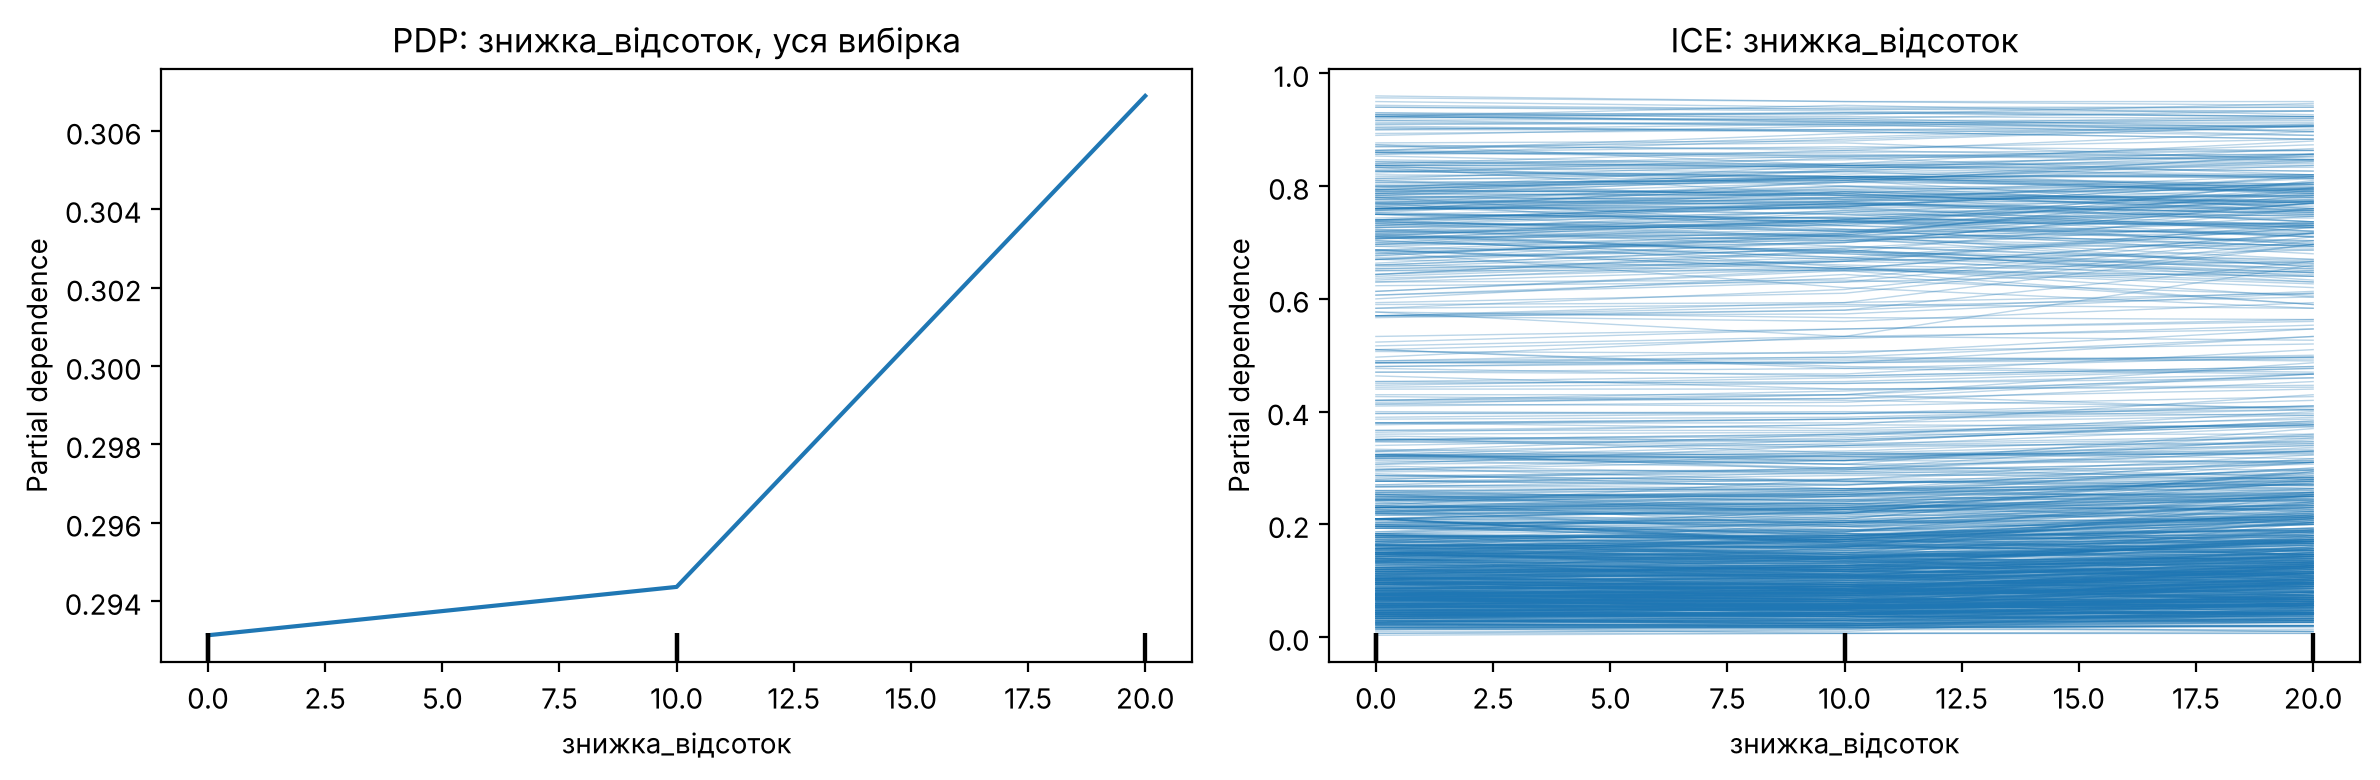

PDP по всій вибірці: {np.float64(0.0): np.float64(0.293), np.float64(10.0): np.float64(0.294), np.float64(20.0): np.float64(0.307)}


In [42]:
# ----- ВАШ КОД: пункт 1 і 2, PDP та ICE для 'знижка_відсоток' -----
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
PartialDependenceDisplay.from_estimator(model, FINAL_X, features=['знижка_відсоток'],
                                        kind='average', ax=ax[0])
ax[0].set_title('PDP: знижка_відсоток, уся вибірка')
PartialDependenceDisplay.from_estimator(model, FINAL_X, features=['знижка_відсоток'],
                                        kind='individual', ax=ax[1], random_state=SEED)
ax[1].set_title('ICE: знижка_відсоток')
plt.tight_layout(); plt.show()

pd_all = partial_dependence(model, FINAL_X, ['знижка_відсоток'], kind='average')
print('PDP по всій вибірці:', dict(zip(pd_all['grid_values'][0], pd_all['average'][0].round(3))))

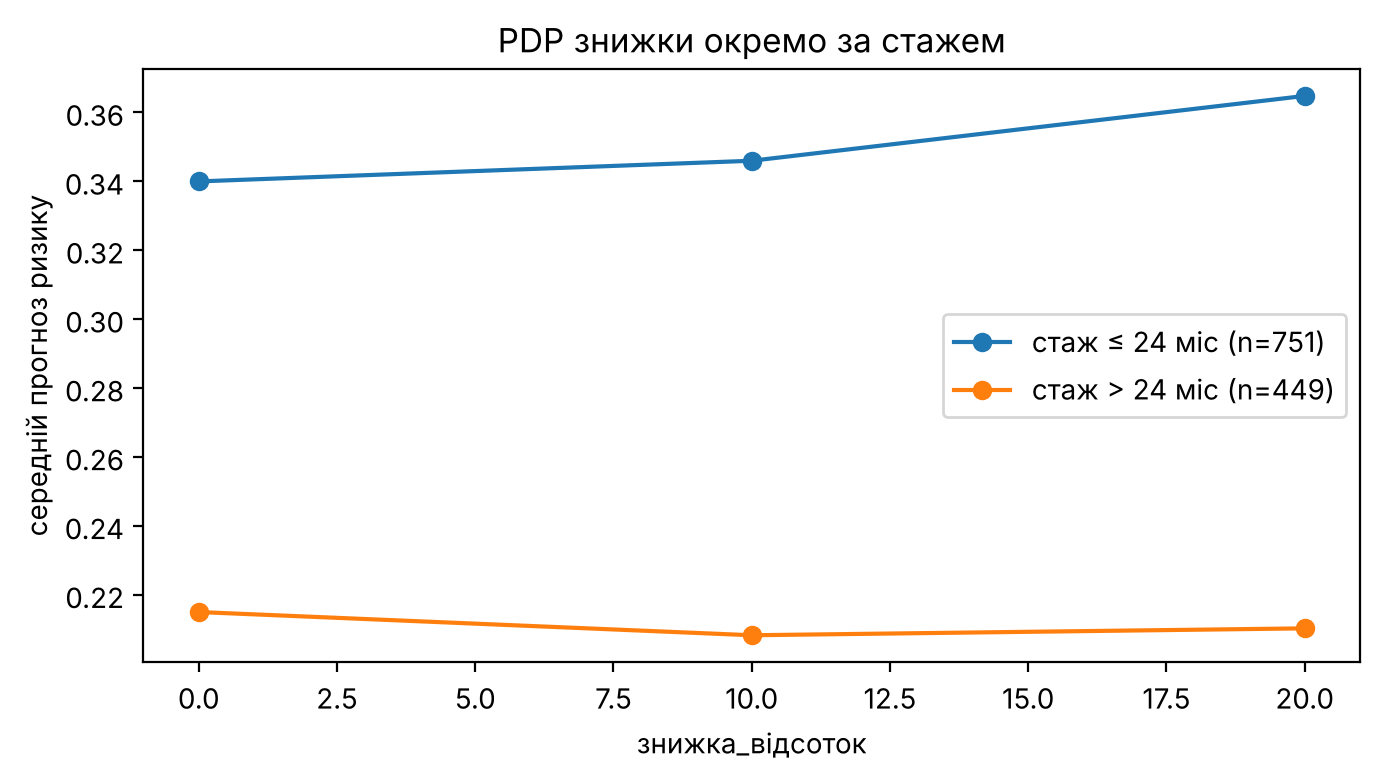

стаж ≤ 24 міс {np.float64(0.0): np.float64(0.34), np.float64(10.0): np.float64(0.346), np.float64(20.0): np.float64(0.365)}
стаж > 24 міс {np.float64(0.0): np.float64(0.215), np.float64(10.0): np.float64(0.208), np.float64(20.0): np.float64(0.21)}


In [43]:
# ----- ВАШ КОД: пункт 3, дві криві на одному рисунку -----
# підказка: partial_dependence(model, FINAL_X[mask], ['знижка_відсоток'], kind='average')
plt.figure(figsize=(7, 4))
pd_groups = {}
for label, mask in [('стаж ≤ 24 міс', FINAL_X['місяців_обслуговування'] <= 24),
                    ('стаж > 24 міс', FINAL_X['місяців_обслуговування'] > 24)]:
    r = partial_dependence(model, FINAL_X[mask], ['знижка_відсоток'], kind='average')
    pd_groups[label] = dict(zip(r['grid_values'][0], r['average'][0].round(3)))
    plt.plot(r['grid_values'][0], r['average'][0], marker='o', label='%s (n=%d)' % (label, mask.sum()))
plt.xlabel('знижка_відсоток'); plt.ylabel('середній прогноз ризику'); plt.legend()
plt.title('PDP знижки окремо за стажем'); plt.tight_layout(); plt.show()
for k, v in pd_groups.items():
    print(k, v)

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [44]:
# ----- ВАШ КОД: зведена таблиця «знижка x група стажу» -> частка відтоку і розмір групи -----
tenure_grp = np.where(raw['місяців_обслуговування'] <= 24, 'стаж ≤ 24 міс', 'стаж > 24 міс')
emp = raw.assign(група_стажу=tenure_grp).pivot_table(
    index='група_стажу', columns='знижка_відсоток', values=TARGET, aggfunc=['mean', 'size'])
emp.columns = [('частка_відтоку' if a == 'mean' else 'клієнтів') + ' @ ' + str(b) + '%' for a, b in emp.columns]
display(emp.round(3))

,частка_відтоку @ 0%,частка_відтоку @ 10%,частка_відтоку @ 20%,клієнтів @ 0%,клієнтів @ 10%,клієнтів @ 20%
група_стажу,,,,,,
стаж > 24 міс,0.263,0.162,0.111,175,148,126
стаж ≤ 24 міс,0.293,0.377,0.438,311,239,201


In [45]:
INTERACTION_FOUND = 'Емпірично знижка діє протилежно у двох групах: у клієнтів зі стажем понад 24 місяці частка відтоку падає з 0,263 (0 %) до 0,162 (10 %) і 0,111 (20 %), а у клієнтів зі стажем до 24 місяців зростає з 0,293 до 0,377 і 0,438; PDP по всій вибірці майже пласкі (0,293 / 0,294 / 0,307), ICE-криві не йдуть в один бік, а PDP за групами відтворює картину лише слабко (до 24 міс: 0,340 → 0,365; понад 24 міс: 0,215 → 0,210), тобто ліс цю взаємодію вловив погано.'     # опишіть, що робить знижка в кожній із двох груп
BUSINESS_ACTION = 'Знижку як засіб утримання варто пропонувати клієнтам зі стажем понад 24 місяці, де з нею відтік нижчий; новим клієнтам (до 24 місяців) знижка в цих даних не пов’язана з утриманням, тож для них потрібен інший захід, а причинність ефекту в обох групах варто перевірити пробною кампанією.'       # що з цього випливає для відділу утримання
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)

Емпірично знижка діє протилежно у двох групах: у клієнтів зі стажем понад 24 місяці частка відтоку падає з 0,263 (0 %) до 0,162 (10 %) і 0,111 (20 %), а у клієнтів зі стажем до 24 місяців зростає з 0,293 до 0,377 і 0,438; PDP по всій вибірці майже пласкі (0,293 / 0,294 / 0,307), ICE-криві не йдуть в один бік, а PDP за групами відтворює картину лише слабко (до 24 міс: 0,340 → 0,365; понад 24 міс: 0,215 → 0,210), тобто ліс цю взаємодію вловив погано.
Знижку як засіб утримання варто пропонувати клієнтам зі стажем понад 24 місяці, де з нею відтік нижчий; новим клієнтам (до 24 місяців) знижка в цих даних не пов’язана з утриманням, тож для них потрібен інший захід, а причинність ефекту в обох групах варто перевірити пробною кампанією.


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [46]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])      # щоб рахувалось за секунди
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 83)


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

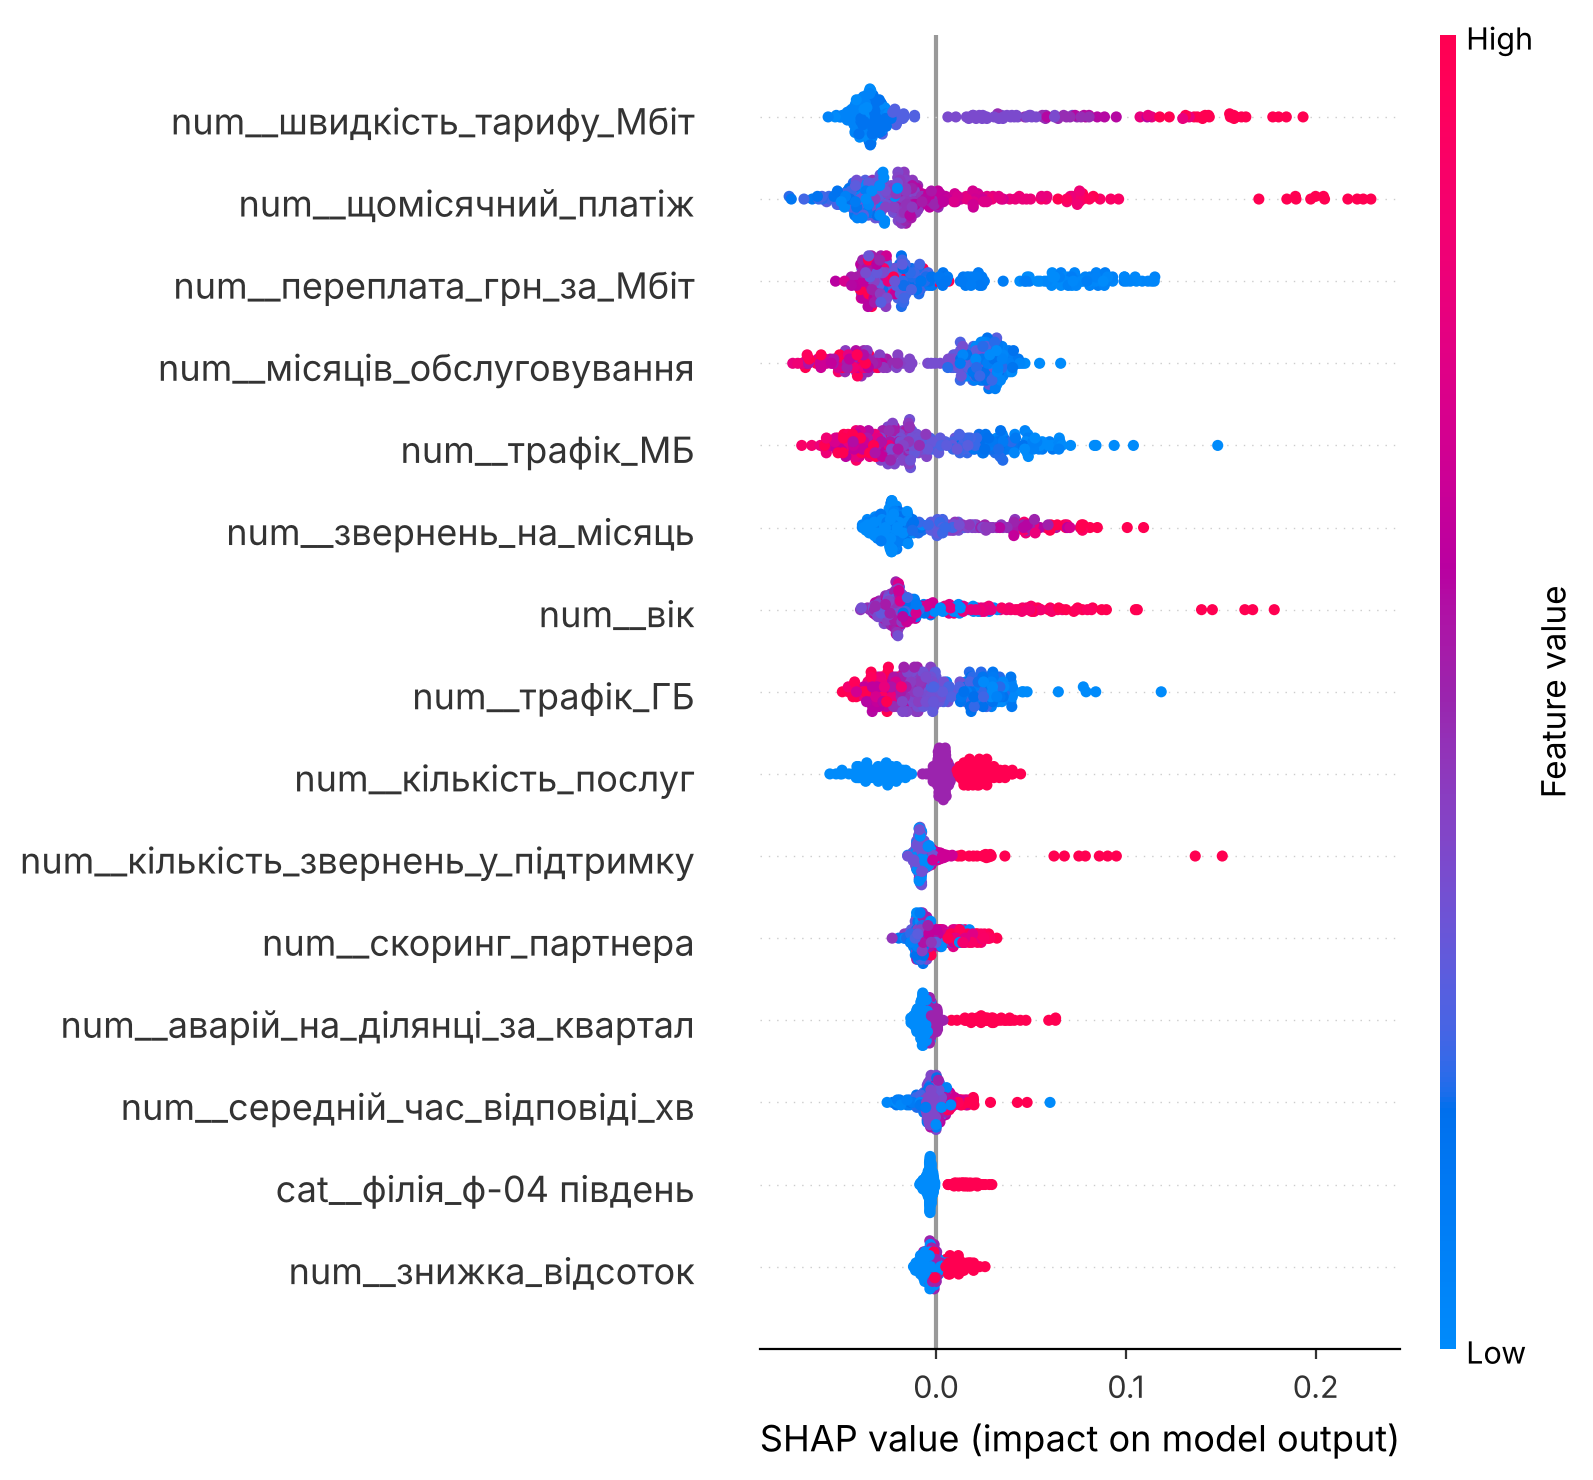

In [47]:
# ----- ВАШ КОД: shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names) -----
shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names, max_display=15)

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [48]:
idx = int(np.argmax(model.predict_proba(Xte)[:SAMPLE, 1]))
print('ризик клієнта: %.3f' % model.predict_proba(Xte)[:SAMPLE, 1][idx])

# ----- ВАШ КОД: три найбільші за модулем внески для цього клієнта -----
contrib = pd.Series(sv1[idx], index=feat_names)
top3 = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(3)
client = Xte.iloc[idx]
base_val = expl.expected_value[1] if np.ndim(expl.expected_value) else expl.expected_value
print('базовий рівень: %.3f; сума внесків + база: %.3f' % (base_val, base_val + contrib.sum()))
display(pd.DataFrame({'внесок': top3.round(3)}))
print('значення цих ознак у клієнта:')
display(client.to_frame('значення'))

ризик клієнта: 0.850
базовий рівень: 0.295; сума внесків + база: 0.850


,внесок
num__щомісячний_платіж,0.204
num__швидкість_тарифу_Мбіт,0.161
num__переплата_грн_за_Мбіт,0.112


значення цих ознак у клієнта:


,значення
вік,45.0
стать,ж
місто,львів
філія,ф-06 приміська
тариф,оптимальний
тип_підключення,оптика
спосіб_оплати,картка
автоплатіж,так
кількість_послуг,3.0
місяців_обслуговування,16.0


In [49]:
EXPLANATION_FOR_MANAGER = 'Ймовірність, що клієнт розірве договір цього кварталу, — 85 % проти 29,5 % у середньому клієнта. Найбільше цю оцінку підвищують три речі: дуже високий щомісячний рахунок — 713 грн (+20 процентних пунктів), найшвидший тариф 1000 Мбіт/с (+16 п.п.) і низька ціна за одиницю швидкості, типова для найдорожчих пакетів (+11 п.п.).'
assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)

Ймовірність, що клієнт розірве договір цього кварталу, — 85 % проти 29,5 % у середньому клієнта. Найбільше цю оцінку підвищують три речі: дуже високий щомісячний рахунок — 713 грн (+20 процентних пунктів), найшвидший тариф 1000 Мбіт/с (+16 п.п.) і низька ціна за одиницю швидкості, типова для найдорожчих пакетів (+11 п.п.).


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [50]:
SHAP_NOT_CAUSAL_FEATURE = 'місяців_обслуговування'
SHAP_NOT_CAUSAL_WHY = 'За Шеплі стаж — одна з ознак із найбільшим внеском (короткий стаж тягне ризик угору, довгий — униз), але стаж неможливо змінити дією відділу утримання: «зробити клієнта давнішим» не можна. Модель цим користується, бо стаж пов’язаний з відтоком у даних, але це не причина, на яку можна вплинути, тому втручання в неї нічого не дасть.'
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)

місяців_обслуговування — За Шеплі стаж — одна з ознак із найбільшим внеском (короткий стаж тягне ризик угору, довгий — униз), але стаж неможливо змінити дією відділу утримання: «зробити клієнта давнішим» не можна. Модель цим користується, бо стаж пов’язаний з відтоком у даних, але це не причина, на яку можна вплинути, тому втручання в неї нічого не дасть.


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [51]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",код_тарифного_плану,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",трафік_МБ + трафік_ГБ,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",місяців_обслуговування,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [52]:
FIFTH_MISTAKE = 'знижка_відсоток на зведеному графіку Шеплі: високі значення знижки (червоні точки) мають додатний внесок, тобто ніби підвищують ризик, і з цього легко зробити висновок «скасуйте знижки — відтік зменшиться». Але емпірична таблиця 10.3б показує, що у клієнтів зі стажем понад 24 місяці зі знижкою 20 % відтік 0,111 проти 0,263 без знижки; додатний внесок — це результат змішування двох груп із протилежним ефектом знижки (див. 10.3), а не причинний ефект знижки.'
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)

знижка_відсоток на зведеному графіку Шеплі: високі значення знижки (червоні точки) мають додатний внесок, тобто ніби підвищують ризик, і з цього легко зробити висновок «скасуйте знижки — відтік зменшиться». Але емпірична таблиця 10.3б показує, що у клієнтів зі стажем понад 24 місяці зі знижкою 20 % відтік 0,111 проти 0,263 без знижки; додатний внесок — це результат змішування двох груп із протилежним ефектом знижки (див. 10.3), а не причинний ефект знижки.


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [53]:
# ----- ВАШ КОД -----
# lift = (частка відтоку серед топ-100) / (частка відтоку в усій перевірковій частині)
TOP_N = 100
risk = model.predict_proba(Xte)[:, 1]
top_idx = np.argsort(-risk)[:TOP_N]
rate_top = float(yte.values[top_idx].mean())
rate_all = float(yte.mean())
lift = rate_top / rate_all
print('у перевірковій частині %d клієнтів, частка відтоку %.3f' % (len(yte), rate_all))
print('серед топ-%d за ризиком пішли %d (частка %.3f)' % (TOP_N, int(yte.values[top_idx].sum()), rate_top))
print('100 навмання дали б у середньому %.1f тих, хто піде' % (TOP_N * rate_all))
print('lift = %.3f' % lift)

у перевірковій частині 360 клієнтів, частка відтоку 0.294
серед топ-100 за ризиком пішли 57 (частка 0.570)
100 навмання дали б у середньому 29.4 тих, хто піде
lift = 1.936


In [54]:
LIFT_MEANING = 'Lift 1,94: якщо обдзвонити 100 клієнтів зі списку за ризиком, серед них буде 57 тих, хто справді піде, проти ≈29 при виборі навмання — тобто зусилля відділу утримання витрачаються майже вдвічі ефективніше.'    # що число lift означає для бізнесу, одним реченням
assert LIFT_MEANING
print(LIFT_MEANING)

Lift 1,94: якщо обдзвонити 100 клієнтів зі списку за ризиком, серед них буде 57 тих, хто справді піде, проти ≈29 при виборі навмання — тобто зусилля відділу утримання витрачаються майже вдвічі ефективніше.


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [55]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_07.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [56]:
_t = cmp_models['с на 100 навчань']
REPORT = '''
1. Метрика — AUC: частка відтоку 0,294, тож модель «ніхто не піде» має точність 0,706 при нульовій користі; AUC не залежить від порога
   і оцінює саме ранжування клієнтів за ризиком, що й потрібно для списку обдзвону. Схема — стратифікована 5-кратна КВ з 4 повторами.

2. Викинуто: id_клієнта — технічний ідентифікатор, нічого не пояснює.
   сума_повернення_депозиту — з'являється при закритті договору (після розірвання);
   код_причини_закриття — записується в момент розірвання;
   обидва заповнені лише у 353 клієнтів, що пішли, показник детектора 1,000.
   кількість_дзвінків_утримання — з'являється після того, як відділ утримання побачив, що клієнт збирається піти; детектор її НЕ знайшов,
   бо поле заповнене в усіх 1200 клієнтів (0 там, де дзвінків не було), пропусків немає і заповненість нічого не розділяє;
   при цьому відтік 0,074 при 0 дзвінків проти 0,63–0,77 при 1–5.
   дата_підключення — артефакт збору (див. п. 4): сходинка в правилі обліку з 2024-04-01.
   Драбина AUC: 0,984 → 0,923 → 0,816 → 0,792.

3. Чесне число: AUC 0,792 ± 0,028 (20 навчань, логістична регресія, 20 ознак). Розкид 0,028 у сім разів більший за 0,004,
   тож різниця 0,004 між середніми двох моделей нічого не означає; порівнювати треба парно: напр., ліс проти логістичної
   +0,0029 ± 0,0094 — у межах шуму.

4. Так. Частка відтоку за кварталом підключення стрибком змінюється з 0,154 (2024Q1) до 0,471 (2024Q2) і лишається 0,43–0,44,
   до того 0,20–0,23; клієнти, підключені після 2024-04-01: відтік 0,449 проти 0,207. Ті самі чесні ознаки передбачають джерело
   (період після дати-зламу) з AUC 0,784 — значно вище за 0,5, тобто період обліку закодований і в інших ознаках.
   За філіями сходинки немає (0,254–0,340). Довіряти моделі в іншій філії можна лише з застереженням: чесне число 0,792
   отримане на суміші двох періодів обліку, тож якщо в іншій філії інше правило обліку, якість треба переміряти на її даних.

5. Жоден шлях не дав значущого приросту. Нові ознаки (переплата за Мбіт, звернень на місяць, є знижка): −0,0026 ± 0,0014
   (значуще, але вниз), практично без додаткового часу. Складніша модель — випадковий ліс: +0,0029 ± 0,0094 (у межах шуму),
   бустинг: −0,0054 ± 0,0099 (у межах шуму); час на 100 навчань: логістична {t_lr} с, ліс {t_rf} с, бустинг {t_hgb} с.
   Значущий приріст дала лише ознака з розділу 10.2б: (вік − 39)² для логістичної регресії: +0,0204 ± 0,0056 (0,790 → 0,810).

6. код_тарифного_плану: вбудована важливість 0,0985 (2-ге місце), перестановочна на перевірковій частині −0,0009.
   Дерево обирає розбиття, що найбільше зменшує неоднорідність на НАВЧАЛЬНИХ даних; 40 рівнів після кодування дають багато
   можливих розбиттів, і якесь із них завжди трохи зменшує неоднорідність випадково — ці дрібні внески сумуються.

7. трафік_ГБ і трафік_МБ (r = 0,9997): у повній моделі перестановочна важливість поділилась — 0,0309 і 0,0170;
   після вилучення трафік_ГБ важливість трафік_МБ зросла до 0,0538. Це не вада методу: він відповідає, наскільки модель
   погіршиться без ознаки, коли друга копія лишається, і модель бере інформацію з неї. Вада — у висновку «важливість мала,
   отже ознаку можна викинути».

8. вік: PDP лісу U-подібний — ≈0,31 у 18 років, мінімум ≈0,27 близько 39 років, ≈0,46 у 80 років. Логістична регресія без
   втручання бачить лише монотонну пряму (≈0,21 → ≈0,43). Після додавання (вік − 39)² її AUC зросла на +0,0204 ± 0,0056.

9. На знижка_відсоток: PDP по всій вибірці майже пласкі (0,293 / 0,294 / 0,307 для 0 / 10 / 20 %), а в сирих даних ефект
   різноспрямований: стаж понад 24 міс — відтік 0,263 → 0,162 → 0,111, стаж до 24 міс — 0,293 → 0,377 → 0,438.
   ICE показав, що криві клієнтів не йдуть в один бік і загалом майже пласкі; PDP за групами — до 24 міс 0,340 → 0,365,
   понад 24 міс 0,215 → 0,210: напрям відтворено лише слабко, тобто ліс цю взаємодію вловив погано — питання до моделі.

10. місяців_обслуговування: великий внесок за Шеплі (короткий стаж підвищує ризик), але стаж не можна змінити дією.
   «Модель цим користується» означає, що ознака допомагає розрізняти клієнтів у даних; «це причина» означало б, що зміна
   ознаки змінить результат, — для цього потрібен причинний висновок, якого в даних немає.

11. Lift 1,94: серед 100 найризикованіших клієнтів перевіркової частини (360 клієнтів) пішли 57 (0,570) проти частки 0,294,
   тобто ≈29 при виборі навмання; AUC на відкладеній частині 0,787, чесне КВ-число 0,792 ± 0,028.
   Застереження: модель показує, хто ймовірно піде, а не кого дзвінок утримає — ефект дзвінка і знижки (див. п. 9)
   треба перевіряти окремо; до того ж lift пораховано на одному поділі з 360 клієнтів, тож він має розкид.

Декларація про використання ШІ:
Використано ШІ-асистента Claude (Anthropic) для написання коду комірок ноутбука, виконання обчислень і формулювання відповідей.
Самостійно перевірено: [доповніть, що саме ви перевіряли самостійно].
'''.format(t_lr=_t['логістична регресія'], t_rf=_t['випадковий ліс'], t_hgb=_t['гістограмний бустинг'])
print(REPORT)


1. Метрика — AUC: частка відтоку 0,294, тож модель «ніхто не піде» має точність 0,706 при нульовій користі; AUC не залежить від порога
   і оцінює саме ранжування клієнтів за ризиком, що й потрібно для списку обдзвону. Схема — стратифікована 5-кратна КВ з 4 повторами.

2. Викинуто: id_клієнта — технічний ідентифікатор, нічого не пояснює.
   сума_повернення_депозиту — з'являється при закритті договору (після розірвання);
   код_причини_закриття — записується в момент розірвання;
   обидва заповнені лише у 353 клієнтів, що пішли, показник детектора 1,000.
   кількість_дзвінків_утримання — з'являється після того, як відділ утримання побачив, що клієнт збирається піти; детектор її НЕ знайшов,
   бо поле заповнене в усіх 1200 клієнтів (0 там, де дзвінків не було), пропусків немає і заповненість нічого не розділяє;
   при цьому відтік 0,074 при 0 дзвінків проти 0,63–0,77 при 1–5.
   дата_підключення — артефакт збору (див. п. 4): сходинка в правилі обліку з 2024-04-01.
   Драбина AUC: 0,984 

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.